# Air Quality Index (AQI) Prediction using Machine Learning

This project predicts the Air Quality Index (AQI) using pollutant concentrations
such as PM2.5, PM10, NO2, SO2, CO and O3 using machine learning models.

Dataset: Air Quality Data in India (CPCB)
Goal: Predict AQI and analyze pollution patterns in Delhi.

Importing libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.model_selection import train_test_split

C:\Users\ASUS\AppData\Local\Temp\ipykernel_10260\2656258649.py:1: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


Loading dataset

In [2]:
city = pd.read_csv("../delhi-aqi-prediction-using-ml/data/city_hour.csv")
delhi_ncr = pd.read_csv("../delhi-aqi-prediction-using-ml/data/delhi_ncr_aqi_dataset.csv")

Basic Dataset Inspection

In [11]:
delhi_ncr.info()
delhi_ncr.shape
delhi_ncr.isnull().sum()
delhi_ncr["datetime"] = pd.to_datetime(delhi_ncr["datetime"])
delhi_ncr["Year"] = delhi_ncr["datetime"].dt.year
delhi_ncr["Month"] = delhi_ncr["datetime"].dt.month
delhi_ncr["Day"] = delhi_ncr["datetime"].dt.day
delhi_ncr["Hour"] = delhi_ncr["datetime"].dt.hour
delhi_ncr.columns

# Rename both to SAME format
city.rename(columns={"Datetime": "datetime"}, inplace=True)
delhi_ncr.rename(columns={"datetime": "datetime"}, inplace=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 201664 entries, 0 to 201663
Data columns (total 29 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   datetime      201664 non-null  datetime64[ns]
 1   date          201664 non-null  object        
 2   year          201664 non-null  int64         
 3   month         201664 non-null  int64         
 4   day           201664 non-null  int64         
 5   hour          201664 non-null  int64         
 6   day_of_week   201664 non-null  object        
 7   is_weekend    201664 non-null  int64         
 8   season        201664 non-null  object        
 9   city          201664 non-null  object        
 10  station       201664 non-null  object        
 11  latitude      201664 non-null  float64       
 12  longitude     201664 non-null  float64       
 13  pm25          201664 non-null  float64       
 14  pm10          201664 non-null  float64       
 15  no2           201

Filter Delhi Data

In [18]:
# STEP 1: Rename columns to SAME format
city.rename(columns={"Datetime": "datetime"}, inplace=True)

# STEP 2: Convert datetime (do this BEFORE filtering)
city["datetime"] = pd.to_datetime(city["datetime"])
delhi_ncr["datetime"] = pd.to_datetime(delhi_ncr["datetime"])

# STEP 3: Filter Delhi
city_delhi = city[city["City"] == "Delhi"].copy()

# STEP 4: Merge
combined = pd.merge(city_delhi, delhi_ncr, on="datetime", how="inner")

# STEP 5: Fix AQI
combined.rename(columns={"aqi": "AQI"}, inplace=True)

# STEP 6: Drop leakage + useless columns
combined = combined.drop(columns=[
    "City", "AQI_x", "AQI_Bucket",
    "PM2.5_x", "PM10_x", "NO2_x", "SO2_x", "CO_x", "O3_x"
], errors="ignore")

# STEP 7: Handle missing values
combined["NH3"] = combined["NH3"].fillna(combined["NH3"].median())

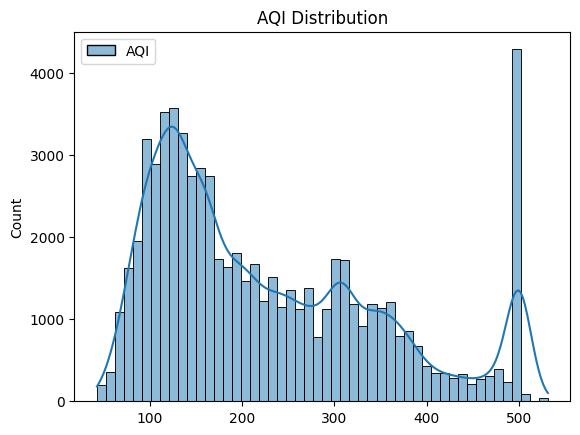

In [19]:


sns.histplot(combined["AQI"], bins=50, kde=True)
plt.title("AQI Distribution")
plt.show()

In [20]:
#fixing outliers
combined["AQI"] = combined["AQI"].replace(500, np.nan)
combined = combined.dropna(subset=["AQI"])

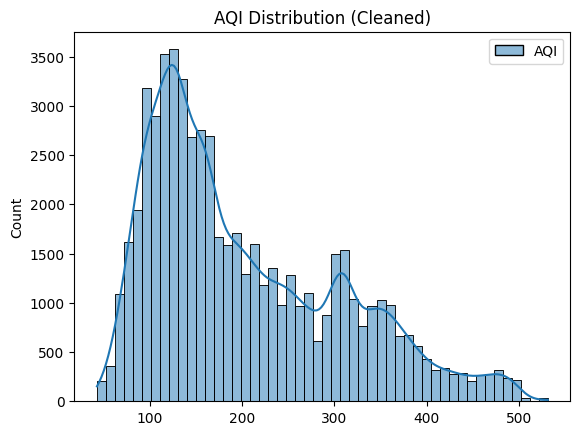

In [21]:
#replotting after fixing outliers
sns.histplot(combined["AQI"], bins=50, kde=True)
plt.title("AQI Distribution (Cleaned)")
plt.show()

In [27]:
combined["AQI"].describe()
combined["AQI"].isnull().sum()
combined["AQI"] = combined["AQI"].fillna(combined["AQI"].median())
combined.columns

Index(['datetime', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2',
       'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'date', 'year', 'month',
       'day', 'hour', 'day_of_week', 'is_weekend', 'season', 'city', 'station',
       'latitude', 'longitude', 'pm25', 'pm10', 'no2', 'so2', 'co', 'o3',
       'temperature', 'humidity', 'wind_speed', 'visibility', 'AQI',
       'aqi_category', 'Year', 'Month', 'Day', 'Hour'],
      dtype='object')

In [24]:
#prepare data for modeling
X = combined.drop("AQI", axis=1)
y = combined["AQI"]

X = X.select_dtypes(include="number")

Feature Engineering (Time Features)

Exploratory Data Analysis

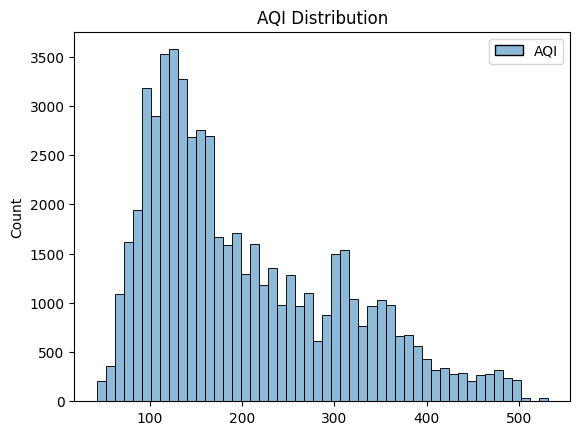

In [26]:
#AQI distribution
sns.histplot(combined["AQI"], bins=50)
plt.title("AQI Distribution")
plt.show()

In [ ]:
combined["AQI"].value_counts().head(10)

AQI
303.0    2139
119.0    2080
116.0    2000
120.0    1950
109.0    1949
302.0    1936
130.0    1898
307.0    1877
127.0    1872
164.0    1869
Name: count, dtype: int64

In [ ]:
#check correlations
corr = combined.select_dtypes(include="number").corr()

corr["AQI"].sort_values(ascending=False)



AQI        1.000000
PM10_y     0.962995
PM2.5_y    0.961611
CO_y       0.898440
NO2_y      0.891719
SO2_y      0.880737
PM2.5_x    0.398582
NO2_x      0.299223
PM10_x     0.251667
NOx        0.241938
NH3        0.144541
SO2_x      0.105491
Hour       0.091634
CO_x       0.064223
O3_x       0.044037
Toluene    0.036613
Benzene    0.023884
NO         0.010786
Xylene    -0.005956
O3_y      -0.248292
Month     -0.845507
Year            NaN
Name: AQI, dtype: float64

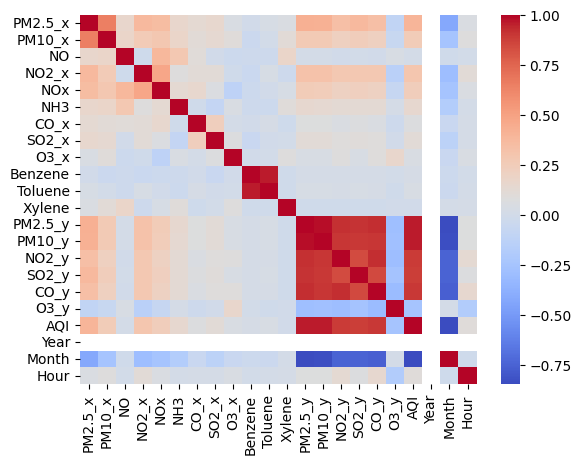

['Datetime', 'PM2.5_x', 'PM10_x', 'NO', 'NO2_x', 'NOx', 'NH3', 'CO_x', 'SO2_x', 'O3_x', 'Benzene', 'Toluene', 'Xylene', 'AQI_Bucket', 'PM2.5_y', 'PM10_y', 'NO2_y', 'SO2_y', 'CO_y', 'O3_y', 'AQI', 'Year', 'Month', 'Hour']


In [ ]:
#heatmap

sns.heatmap(corr, cmap="coolwarm")
plt.show()
print(combined.columns.tolist())

In [ ]:
# Feature selection was performed using correlation analysis.
# Highly correlated pollutants like PM2.5 and PM10 were kept,
# while weakly correlated features were removed.

# Dropping useless + duplicate
combined.drop(columns=[
    "City", "Datetime", "AQI_x", "AQI_Bucket",
    "Benzene", "Toluene", "Xylene"
], inplace=True, errors='ignore')

# Drop all _x columns
combined = combined[[col for col in combined.columns if "_x" not in col]]

if "Year" in combined.columns and combined["Year"].nunique() == 1:
    combined.drop("Year", axis=1, inplace=True)

In [ ]:
combined.info()
combined.head()

<class 'pandas.core.frame.DataFrame'>
Index: 376866 entries, 11 to 424947
Data columns (total 12 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   NO       376866 non-null  float64
 1   NOx      376866 non-null  float64
 2   NH3      376866 non-null  float64
 3   PM2.5_y  376866 non-null  float64
 4   PM10_y   376866 non-null  float64
 5   NO2_y    376866 non-null  float64
 6   SO2_y    376866 non-null  float64
 7   CO_y     376866 non-null  float64
 8   O3_y     376866 non-null  float64
 9   AQI      376866 non-null  float64
 10  Month    376866 non-null  int32  
 11  Hour     376866 non-null  int32  
dtypes: float64(10), int32(2)
memory usage: 34.5 MB


,NO,NOx,NH3,PM2.5_y,PM10_y,NO2_y,SO2_y,CO_y,O3_y,AQI,Month,Hour
11,3.97,6.91,12.75,269.8,488.6,89.8,15.9,4.23,21.5,473.0,1,6
13,3.97,6.91,12.75,248.2,424.5,94.7,16.4,4.38,24.5,399.0,1,6
24,1.51,8.43,12.75,233.4,426.8,72.2,30.4,3.99,24.6,396.0,1,12
27,1.51,8.43,12.75,215.4,349.5,66.6,13.2,3.37,26.4,373.0,1,12
29,1.51,8.43,12.75,212.5,427.2,88.3,13.0,2.63,21.6,396.0,1,12


Prepare Data for Machine Learning

In [ ]:
# Split features and target
X = combined[["NO", "NOx", "NH3", "Hour"]]
y = combined["AQI"]

Train-test split

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

Train Models

In [ ]:
# Linear Regression
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

print("LR R2:", r2_score(y_test, y_pred_lr))

LR R2: 0.09170560416644036


In [ ]:
# Random Forest
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(n_estimators=100, random_state=42)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

from sklearn.metrics import r2_score, mean_squared_error

print("R2 Score:", r2_score(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred, squared=False))


R2 Score: 0.8837928172970229
RMSE: 37.58363693356561


c:\AirVision\.venv\Lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


In [ ]:
import joblib

joblib.dump(model, "aqi_model.pkl")

['aqi_model.pkl']

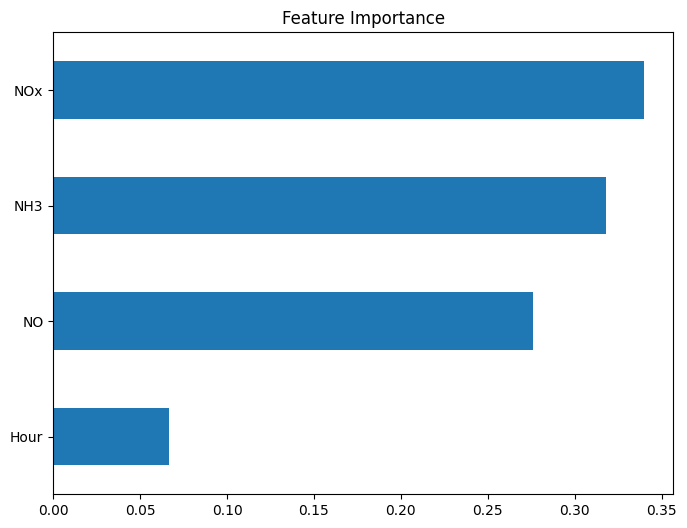

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(model.feature_importances_, index=X.columns)
importance.sort_values().plot(kind='barh', figsize=(8,6))

plt.title("Feature Importance")
plt.show()

Model Evaluation


In [ ]:
def predict_aqi(NO, NOx, NH3, Hour):
    input_data = [[NO, NOx, NH3, Hour]]
    prediction = model.predict(input_data)
    return prediction[0]

In [ ]:
predict_aqi(5, 10, 20, 14)

c:\AirVision\.venv\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


145.72731018611393

Actual vs Predicted Plot

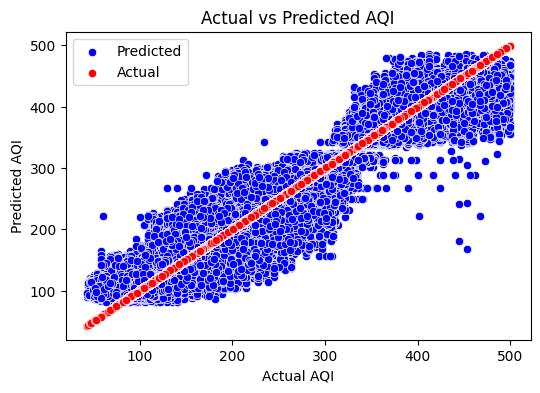

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))

sns.scatterplot(x=y_test, y=y_pred, color="blue", label="Predicted")
sns.scatterplot(x=y_test, y=y_test, color="red", label="Actual")

plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title("Actual vs Predicted AQI")
plt.legend()

plt.show()

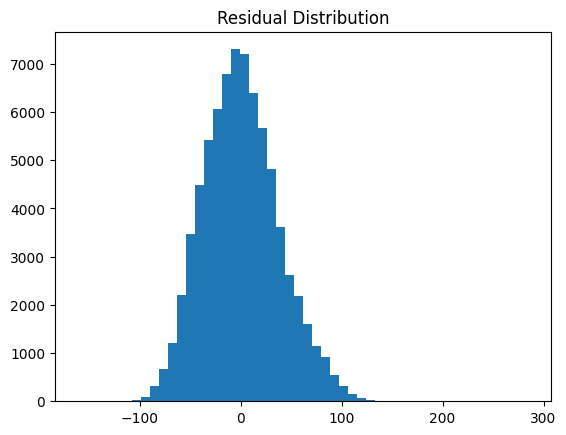

In [ ]:
residuals = y_test - y_pred

plt.hist(residuals, bins=50)
plt.title("Residual Distribution")
plt.show()

In [ ]:
def aqi_category(aqi):
    if aqi <= 50: return "Good"
    elif aqi <= 100: return "Satisfactory"
    elif aqi <= 200: return "Moderate"
    elif aqi <= 300: return "Poor"
    elif aqi <= 400: return "Very Poor"
    else: return "Severe"

In [ ]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=150,
    max_depth=10,
    random_state=42
)

Support Vector Regression

In [ ]:

from sklearn.svm import LinearSVR
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

svr = LinearSVR(random_state=42)

svr.fit(X_train_scaled, y_train)

y_pred_svr = svr.predict(X_test_scaled)

from sklearn.metrics import r2_score, mean_squared_error

print("Linear SVR R2:", r2_score(y_test, y_pred_svr))
print("RMSE:", mean_squared_error(y_test, y_pred_svr)**0.5)

Linear SVR R2: 0.051146443799895636
RMSE: 107.394468421514


KNN Regression

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn = KNeighborsRegressor(n_neighbors=5)

knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)

print("KNN R2:", r2_score(y_test, y_pred_knn))
print("KNN RMSE:", mean_squared_error(y_test, y_pred_knn)**0.5) 


KNN R2: 0.8632016033719447
KNN RMSE: 40.777708920803555


In [ ]:
for k in [3, 5, 7, 9]:
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred = knn.predict(X_test_scaled)
    
    print(f"K={k} → R2:", r2_score(y_test, y_pred))

K=3 → R2: 0.8511091786730558
K=5 → R2: 0.8632016033719447
K=7 → R2: 0.865733899258625
K=9 → R2: 0.8649173470012348


Model Comparison Table

In [ ]:
import pandas as pd
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Calculate metrics safely
lr_rmse = mean_squared_error(y_test, y_pred_lr)**0.5
knn_rmse = mean_squared_error(y_test, y_pred_knn)**0.5
svr_rmse = mean_squared_error(y_test, y_pred_svr)**0.5
rf_rmse = mean_squared_error(y_test, y_pred)**0.5

lr_mae = mean_absolute_error(y_test, y_pred_lr)
knn_mae = mean_absolute_error(y_test, y_pred_knn)
svr_mae = mean_absolute_error(y_test, y_pred_svr)
rf_mae = mean_absolute_error(y_test, y_pred)

# Create results table
results = pd.DataFrame({
    "Model": ["Linear Regression", "KNN", "Linear SVR", "Random Forest"],
    "R2 Score": [
        r2_score(y_test, y_pred_lr),
        r2_score(y_test, y_pred_knn),
        r2_score(y_test, y_pred_svr),
        r2_score(y_test, y_pred)
    ],
    "RMSE": [
        lr_rmse,
        knn_rmse,
        svr_rmse,
        rf_rmse
    ],
    "MAE": [
        lr_mae,
        knn_mae,
        svr_mae,
        rf_mae
    ]
})

# Sort results
results = results.sort_values(by="R2 Score", ascending=False)

print(results)

               Model  R2 Score        RMSE        MAE
3      Random Forest  0.864917   40.521182  31.365897
1                KNN  0.863202   40.777709  32.008019
0  Linear Regression  0.091706  105.074089  87.902748
2         Linear SVR  0.051146  107.394468  86.543036


Error distribution plot

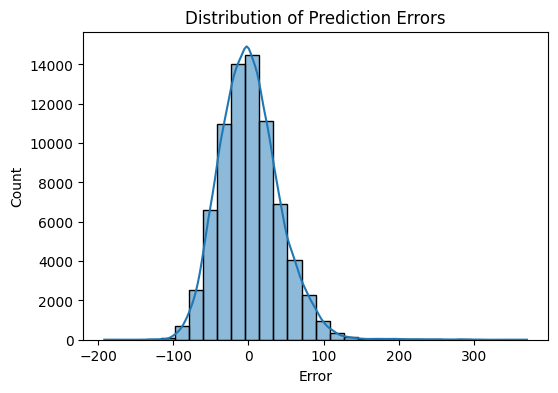

In [ ]:
import seaborn as sns

errors = y_test - y_pred

plt.figure(figsize=(6,4))
sns.histplot(errors, bins=30, kde=True)
plt.title("Distribution of Prediction Errors")
plt.xlabel("Error")
plt.show()

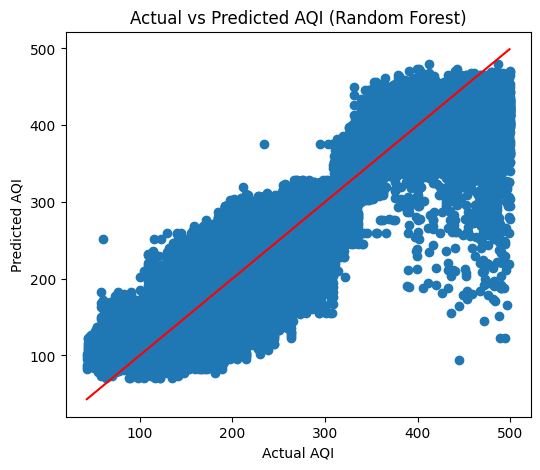

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))
plt.scatter(y_test, y_pred)

plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title("Actual vs Predicted AQI (Random Forest)")

plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color='red')

plt.show()

In [ ]:
#K fold cross validation
from sklearn.model_selection import cross_val_score

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(),
    "Random Forest": RandomForestRegressor(),
    "KNN": KNeighborsRegressor()
}

for name, model in models.items():
    
    scores = cross_val_score(model, X, y, cv=5, scoring='r2')
    
    print(name)
    print("Average R2:", scores.mean())
    print("---------------")

Linear Regression
Average R2: -0.2538095694230141
---------------
Decision Tree
Average R2: -0.6927169495271736
---------------
Random Forest
Average R2: -0.2214911674079337
---------------
KNN
Average R2: -0.6770798801693495
---------------


In [ ]:
def data_quality_report(df):
    print("Shape:", df.shape)
    print("\nMissing Values:\n", df.isnull().mean() * 100)

    print("\nDuplicates:", df.duplicated().sum())

    print("\nConstant Columns:",
          [col for col in df.columns if df[col].nunique() == 1])

    print("\nHigh Null Columns:",
          [col for col in df.columns if df[col].isnull().mean() > 0.5])

    print("\nID-like Columns:",
          [col for col in df.columns if df[col].nunique() == len(df)])

    print("\nHigh Zero Columns:",
          [col for col in df.select_dtypes(include=np.number).columns
           if (df[col] == 0).mean() > 0.9])

ARIMA IMPLEMENTATION

In [ ]:
ts = combined.set_index("Datetime")["AQI"]
ts = ts.sort_index()

KeyError: "None of ['Datetime'] are in the columns"